# Занятие 7. Находим лишние вызовы и считаем расходы агента

Пользователь просит маршрут на выходные и ждет готовый ответ. У разработчика другой вопрос: почему подготовка заняла столько времени?
Сегодня подключим Langfuse к знакомому `create_agent`, найдем лишний вызов модели и проверим, что изменилось после исправления.
Потом сохраним промпт в Langfuse, переключим его версию и убедимся, что агент действительно использовал новый текст.

Результат занятия: по конкретному прогону можно объяснить, какие инструменты сработали, сколько было обращений к модели и во что они обошлись.
Для практики понадобится свой агент. Начать можно с одного запроса, который сейчас трудно объяснить по обычному ответу в чате.


## Что увидит пользователь и что нужно выяснить разработчику

Учебный помощник находит места в небольшом каталоге и составляет маршрут по Амстердаму.
После готового ответа приложение вызывает модель еще раз, чтобы сделать текст дружелюбнее. Пользователь получает только последнюю версию.
Нужно выяснить, оправдан ли отдельный вызов ради стиля, и сравнить его с инструкцией о тоне в основном промпте.

Схема показывает последовательность работы. Числа появятся после запуска: заранее неизвестно, сколько секунд и токенов займет каждый этап.

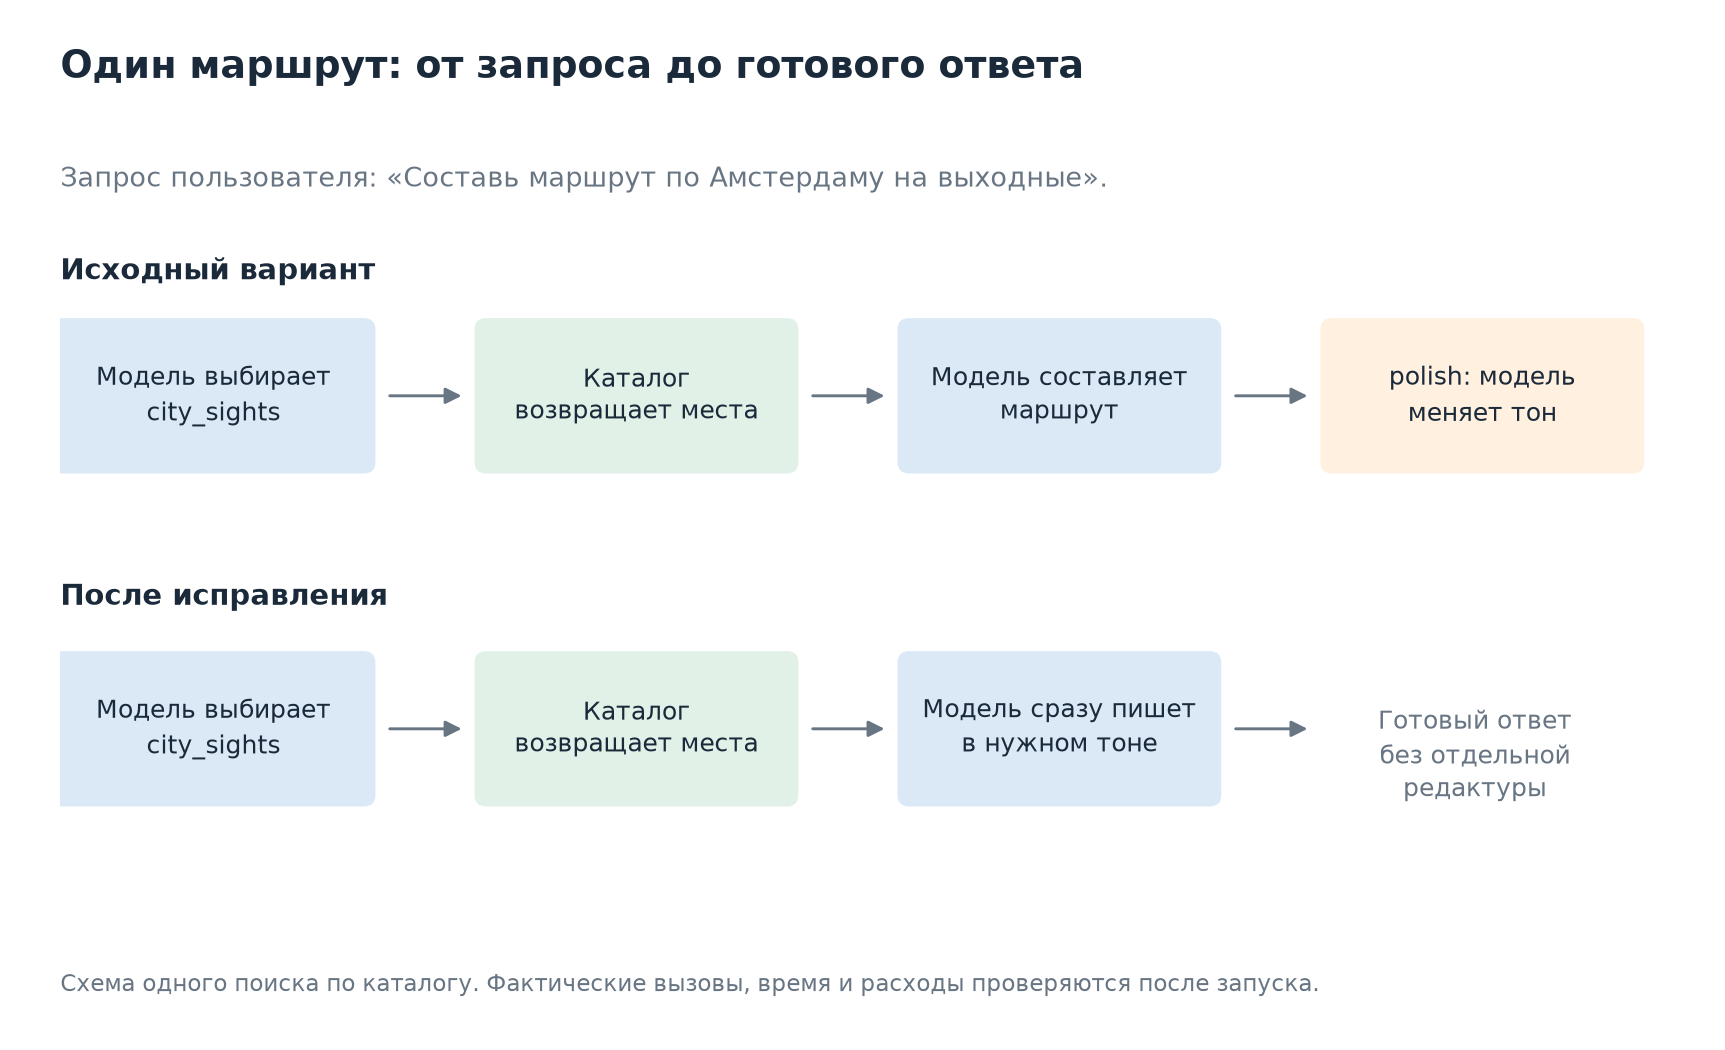


In [ ]:
# Подключить модель через настройки окружения курса.

import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()


def chat_model(size="cheap", **kwargs):
    name = os.environ[f"MODEL_{size.upper()}"]
    secret = os.environ["LLM_API_KEY"]
    kwargs.setdefault("timeout", 120)  # ограничить ожидание ответа провайдера
    kwargs.setdefault("max_tokens", 8192)
    if os.getenv("LLM_REASONING_EFFORT"):
        kwargs.setdefault("reasoning_effort", os.environ["LLM_REASONING_EFFORT"])
    # У Gemini собственный адаптер; остальные настройки курса используют совместимый API.
    if os.getenv("LLM_PROVIDER", "openai_compat") == "google_genai":
        return init_chat_model(f"google_genai:{name}", api_key=secret, **kwargs)
    return init_chat_model(
        f"openai:{name}", api_key=secret, base_url=os.environ["LLM_BASE_URL"], **kwargs
    )


model = chat_model()
print("Model:", os.environ["MODEL_CHEAP"])


## Готовим небольшой пример

Инструмент `city_sights` читает учебный каталог. Сетевого поиска здесь нет, поэтому источник сведений одинаковый в обоих вариантах агента.
`@tool` передает модели описание функции и схему ее аргументов; сам поиск выполняет Python.
Прямой вызов внизу проверяет каталог до обращения к модели.


In [ ]:
# Дать агенту инструмент поиска по учебному каталогу.

from langchain_core.tools import tool

SIGHTS = {
    "amsterdam": (
        "Gifu Ramen Bar (Elandsgracht 14, Jordaan): ramen and izakaya; "
        "Shoyu Tori Chintan with yuzu; book ahead.\n"
        "Advocatuur (Prinsengracht 432, Rosewood hotel): cocktail bar; "
        "house jenever and Indian-style small plates.\n"
        "Blin Queen (Amstel 102): sweet and savory blini; smoked salmon blini; closed Mondays.\n"
        "DAK Showroom (Bellamyplein 16H, Oud-West): specialty coffee tasting room and shop; until 17:00.\n"
        "Fabus (De Clercqstraat 105H): natural wine bar with Lebanese small plates.\n"
        "taal.coffee (J.J. Cremerplein 34H, West): specialty coffee, house drinks and Five Ways beans.\n"
        "murmur (Aambeeldstraat 60, Noord): listening bar, DJs, Lebanese food, wine and terrace; check hours."
    ),
    "porto": "Livraria Lello; the Ribeira riverfront; port wine cellars; Dom Luis I bridge",
}


@tool
def city_sights(city: str) -> str:
    """Look up places in the course's city catalogue: amsterdam or porto."""
    key = city.strip().lower()  # Amsterdam и amsterdam обращаются к одной записи
    # При промахе модель получает подсказку, какие города доступны.
    return SIGHTS.get(key, f"Unknown city. Available cities: {', '.join(SIGHTS)}.")


print(city_sights.invoke({"city": "Amsterdam"}))


## Откуда берется дополнительный вызов

`create_agent` уже умеет обращаться к модели и выполнять инструменты. К нему добавлен один знакомый хук `after_agent`.
Функция `polish` получает готовый ответ, отправляет его модели с просьбой изменить тон и добавляет переписанный ответ в сообщения.
Внутри хука используется модель без инструментов: здесь требуется только редактура текста.

Этот шаг специально оставлен отдельным, чтобы его можно было найти в трейсе и оценить по данным.
`InMemorySaver` хранит историю учебного разговора. Для поиска лишнего вызова достаточно памяти текущего ядра Jupyter.


In [ ]:
# Собрать агента с дополнительной редактурой готового ответа.

from langchain.agents import create_agent
from langchain.agents.middleware import after_agent
from langgraph.checkpoint.memory import InMemorySaver

PLAN_PROMPT = (
    "You plan weekend city trips using the course catalogue. "
    "Call city_sights once before the first itinerary. "
    "For follow-ups, reuse the catalogue already in the conversation. "
    "Use venue names without street addresses. "
    "Write one paragraph, at most 100 words. Do not invent opening hours or prices. "
    "Give a complete itinerary for Saturday and Sunday. "
    "Only the itinerary: no introduction, sign-off, questions or follow-up offers."
)
POLISH_PROMPT = (
    "Rewrite this itinerary in a warm, friendly tone. Keep all facts and format, at most 100 words. "
    "Do not make the text longer. "
    "Return only the itinerary: no introduction, sign-off, questions or follow-up offers."
)


@after_agent
def polish(state, runtime):
    draft = state["messages"][-1].content  # готовый ответ основного агента
    # Переписывание запускает еще один платный запрос, хотя маршрут уже готов.
    reply = model.invoke([("system", POLISH_PROMPT), ("user", draft)])
    return {"messages": [reply]}


wasteful = create_agent(
    model=model, tools=[city_sights], system_prompt=PLAN_PROMPT,
    middleware=[polish], checkpointer=InMemorySaver(),
)
QUESTION = "Plan a weekend in Amsterdam."


## Сначала войти в Langfuse, затем подключить ноутбук

Откройте адрес учебного Langfuse. В поле `Email` нужен полный адрес почты, а не имя `admin`.
Для браузера используются почта и пароль учетной записи. Ключи `LANGFUSE_PUBLIC_KEY` и `LANGFUSE_SECRET_KEY` нужны Python и не подходят для формы входа.
После входа выберите организацию курса и проект `My assistant`, затем откройте `Tracing` слева.
При работе со своим сервером название проекта может отличаться; он должен соответствовать API-ключам в `.env`.

Следующая ячейка проверяет доступ Python к проекту и создает `CallbackHandler`, который будет отправлять события работы агента.
`lesson_id` помечает текущий Run All: по нему можно отличить новые записи от предыдущих запусков.
Пароль браузерной учетной записи преподаватель передает отдельно; в ноутбуке его хранить не нужно.


In [ ]:
# Проверить подключение к Langfuse и создать обработчик событий.

from uuid import uuid4
from langfuse import get_client
from langfuse.langchain import CallbackHandler

langfuse = get_client()
assert langfuse.auth_check(), "Check the Langfuse URL and project keys in .env"
handler = CallbackHandler()
lesson_id = uuid4().hex[:10]  # повторный Run All получает отдельные учебные записи
USER_ID = os.getenv("COURSE_USER_ID", "demo-student")
print("Langfuse connection: OK")
print("Lesson run:", lesson_id)


## Зачем нужны настройки прогона

После нескольких запусков в Langfuse появятся похожие записи. Нужно отличить исходный вариант от исправленного и собрать сообщения одного разговора вместе.
Для записи событий достаточно передать `callbacks: [handler]` в настройки вызова агента. Остальные поля помогают находить и группировать записи.

- `run_name`: имя строки в `Tracing`, например `trip/before` или `trip/after`.
- `langfuse_tags`: метки для фильтрации по занятию, текущему Run All и варианту агента.
- `langfuse_user_id`: идентификатор пользователя приложения; по нему можно найти его запросы. Это не логин в Langfuse.
- `langfuse_session_id`: объединяет несколько запросов одного разговора на экране `Sessions`.

Знакомый `thread_id` выбирает историю в чекпоинтере; метаданные Langfuse историю не сохраняют. Здесь оба идентификатора равны для удобства.
Для продолжения разговора повторно передается тот же `config`. Вызов `trace_config()` создает настройки нового разговора.
`recursion_limit` ограничивает число шагов агента и к настройке Langfuse не относится.


In [ ]:
# Включить запись событий и подписать прогон для поиска в Langfuse.

def trace_config(label):
    session_id = f"s07-{lesson_id}-{label}-{uuid4().hex[:6]}"
    return {
        "run_name": f"trip/{label}",
        "recursion_limit": 12,
        "configurable": {"thread_id": session_id},  # история разговора в чекпоинтере
        "callbacks": [handler],  # отправлять события модели и инструментов в Langfuse
        "metadata": {
            "langfuse_session_id": session_id,  # группировка трейсов в интерфейсе
            "langfuse_user_id": USER_ID,
            "langfuse_tags": ["session-07", lesson_id, label],
        },
    }


## Что измеряем при запуске

Для каждого обращения нужны время ожидания, число вызовов модели, токены и стоимость, которую сообщил провайдер.
Готовая функция `summarize_run` из файла [lesson07_metrics.py](lesson07_metrics.py) собирает эти поля из ответов модели. Ее код и тесты разберем ниже.
Если часть данных отсутствует, отчет возвращает `None`. Так неизвестная стоимость не превращается в ноль.

Функция `run_trip` ниже запускает агента и возвращает результат вместе со ссылкой на трейс и отчетом.
При продолжении разговора она считает только новые сообщения: предыдущие ходы уже были оплачены и не должны попадать в сумму повторно.
Время `flush()` не входит во время ожидания ответа: это доставка записей в Langfuse после завершения работы агента.
Этот помощник рассчитан на последовательные вызовы ноутбука; при параллельных запросах сервера идентификатор трейса нужно связывать с контекстом каждого запроса.


In [ ]:
# Подключить функцию отчета из файла рядом с ноутбуком.

from lesson07_metrics import summarize_run
from time import perf_counter


In [ ]:
# Запустить один запрос и сохранить отчет вместе со ссылкой на Langfuse.

def run_trip(agent, question, config):
    # Сохранить границу истории до добавления нового вопроса.
    history_size = len(agent.get_state(config).values.get("messages", []))
    started = perf_counter()
    result = agent.invoke({"messages": [("user", question)]}, config=config)
    elapsed = perf_counter() - started
    # Старые ответы не должны повторно попасть в расходы.
    new_messages = result["messages"][history_size:]
    trace_id = handler.last_trace_id  # трейс последнего завершенного invoke
    langfuse.flush()  # доставка событий не включена во время ответа
    return {
        "result": result,
        "metrics": summarize_run(new_messages, elapsed),
        "trace_id": trace_id,
        "url": langfuse.get_trace_url(trace_id=trace_id),
    }


In [ ]:
# Выполнить исходный вариант и открыть его трейс в Langfuse.

before = run_trip(wasteful, QUESTION, trace_config("before"))
print(before["result"]["messages"][-1].content)
print("Metrics:", before["metrics"])
print("Trace:", before["url"])


## Открываем запрос и находим лишний вызов

Нажмите ссылку после `Trace:` в выводе предыдущей ячейки. Она ведет прямо к этому запуску.
Через список: `Tracing → Traces`, выберите период, включающий запуск, вставьте идентификатор из ссылки в `Search` и нажмите Enter.
Откройте строку `trip/before`. Если появилась узкая боковая панель, нажмите `Expand` в ее правом верхнем углу.

1. Выберите первый `ChatOpenAI`: в `System` инструкция, в `User` вопрос, в `Assistant` вызов `city_sights` с аргументом `city=amsterdam`.
2. Нажмите `city_sights`: в `Input` город, в `Output → content` найденные места.
3. Выберите следующий `ChatOpenAI`: внизу `Preview` уже есть готовый маршрут. `Show 2 more ...` раскрывает свернутые сообщения.
4. Выберите `ChatOpenAI` под `polish.after_agent`: в `User` снова готовый маршрут, а `System` просит переписать его дружелюбнее.

Вверху каждой записи видны `Latency` и токены. На снимке последний вызов занял 1,31 с; при новом запуске числа будут другими.
Следующая ячейка забирает время этих операций через API для графика в ноутбуке. Повторного запроса к модели не будет.
Не складывайте время родительских и дочерних строк: длительность родителя уже включает его дочерние операции.

Снимок сделан 10 ноября 2026 года по учебному прогону с Амстердамом от 10 ноября; интерфейс Langfuse 3.224.0.

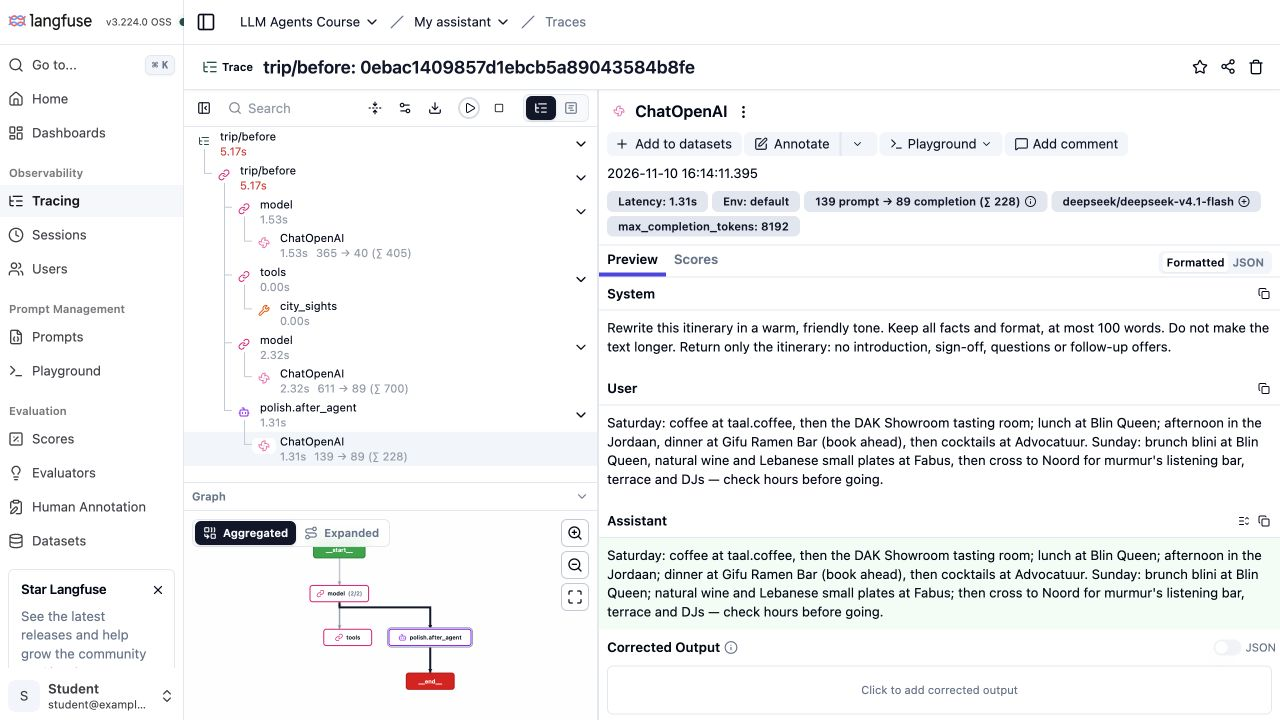


In [ ]:
# Получить операции исходного прогона для графика времени.

from time import sleep


def read_trace(run):
    # Найти запись по trace_id из результата run_trip.
    for attempt in range(20):
        try:
            trace = langfuse.api.trace.get(run["trace_id"])
        except Exception as error:
            # 404: сервер еще не подготовил запись; остальные ошибки нужно показать.
            if getattr(error, "status_code", None) != 404:
                raise
        else:
            # Ждать все завершенные вызовы модели, посчитанные в run_trip.
            generations = [item for item in trace.observations if item.type == "GENERATION"]
            if len(generations) >= run["metrics"]["model_calls"] and all(item.end_time for item in generations):
                return trace
        sleep(0.5)  # повторяется чтение Langfuse, а не работа агента
    raise TimeoutError("Trace is not fully indexed yet; retry this cell.")


# Взять исходный прогон; оставить модель и инструмент, отсортировать по началу.
before_trace = read_trace(before)
operations = sorted(
    [item for item in before_trace.observations if item.type in {"GENERATION", "TOOL"}],
    key=lambda item: item.start_time,
)
for item in operations:
    print(item.type, (item.metadata or {}).get("langgraph_node", item.name), item.latency)


In [ ]:
# Показать время операций по данным текущего трейса Langfuse.

import matplotlib.pyplot as plt

origin = operations[0].start_time  # начало шкалы, без календарной даты
starts = [(item.start_time - origin).total_seconds() for item in operations]
durations = [(item.end_time - item.start_time).total_seconds() for item in operations]
names = [(item.metadata or {}).get("langgraph_node", item.name) for item in operations]

# Цвет выделяет вызов ради редактуры готового ответа.
colors = ["#c87b36" if "polish" in name else "#416d9c" for name in names]

fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
ax.barh(range(len(names)), durations, left=starts, color=colors)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set(xlabel="Секунды от начала первой операции", title="Где проходит время запроса")
ax.spines[["top", "right"]].set_visible(False)
for i, (start, duration) in enumerate(zip(starts, durations)):
    caption = f"{duration:.3f} с" if duration >= 0.001 else "меньше 1 мс"
    if duration < 0.001:
        ax.scatter(start, i, marker="|", color=colors[i], s=150)
    ax.text(start + duration + 0.03, i, caption, va="center", fontsize=10)
ax.set_xlim(right=max(s + d for s, d in zip(starts, durations)) * 1.18 + 0.1)
plt.show()


## Где смотреть токены и стоимость

В `Tracing → Traces` откройте `Columns` и оставьте `Name`, `Latency`, `Tokens`, `Total Cost`; служебные колонки остаются автоматически.
На снимке у `trip/before` видны 5,17 с и 1115 входных + 218 выходных токенов. Ячейка `Total Cost` пустая.
Для того же трейса API возвращает `total_cost=0.0`. Это поле стоимости Langfuse в USD, а не сумма из ответа Polza.

В выводе ячейки с `before` строка `Metrics:` содержит словарь `before["metrics"]`: вызовы, время, токены и рубли за весь запуск.
Его `cost_rub` — сумма значений, которые Polza вернула в `response_metadata["token_usage"]["cost_rub"]` у новых ответов модели.
Следующая ячейка отдельно показывает стоимость первого вызова, всего запуска и поле Langfuse, чтобы не смешивать эти числа.

Для прогона на снимке Polza вернула 0,03248938 руб. за три вызова. В Langfuse нет подходящего определения цены этой модели — проверка показана дальше.
Пустая ячейка `Total Cost` поэтому не означает бесплатный запуск. Сумма из Polza при этом доступна в ответах модели и выводе ноутбука.
Если провайдер не вернул `cost_rub`, результат будет `None`: по этим данным стоимость неизвестна. Рубли нельзя записывать в поле USD без пересчета.
Токены берутся из `usage_metadata`; входные включают прочитанное из кеша. При использовании суммы Polza повторно прибавлять плату за кеш не нужно.

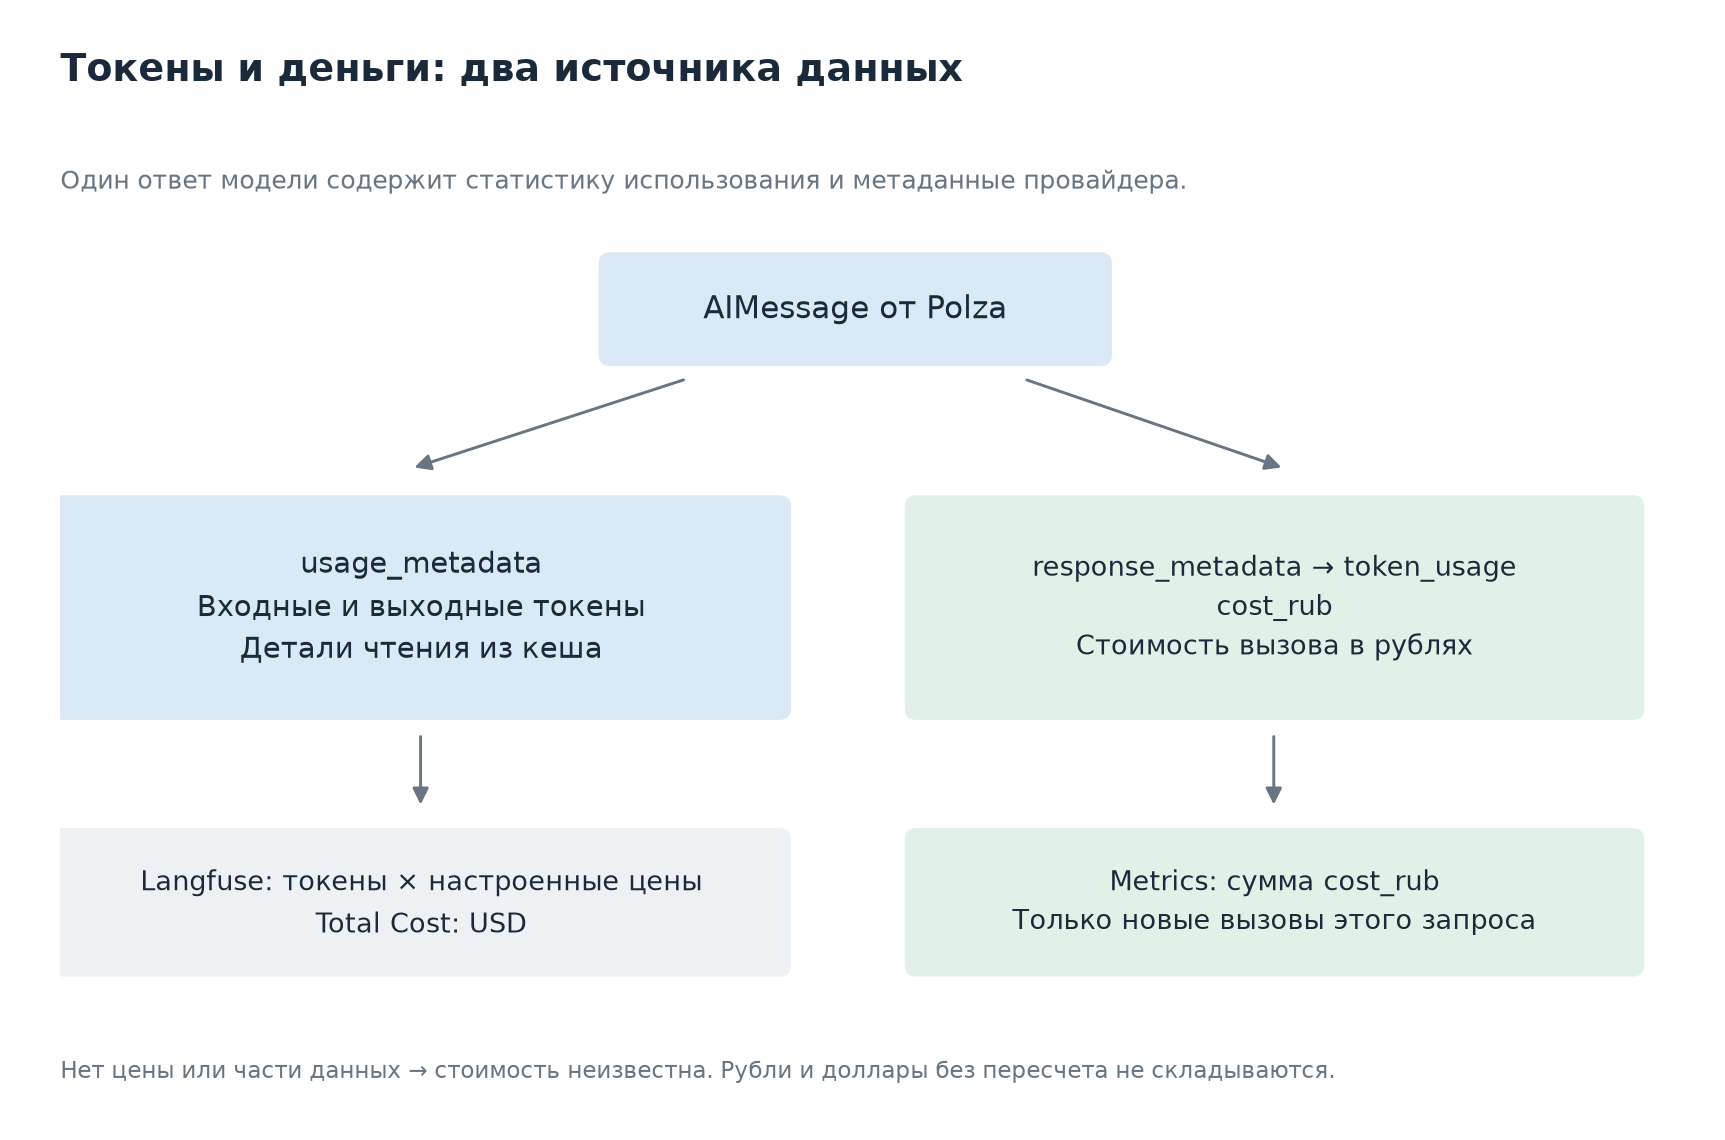

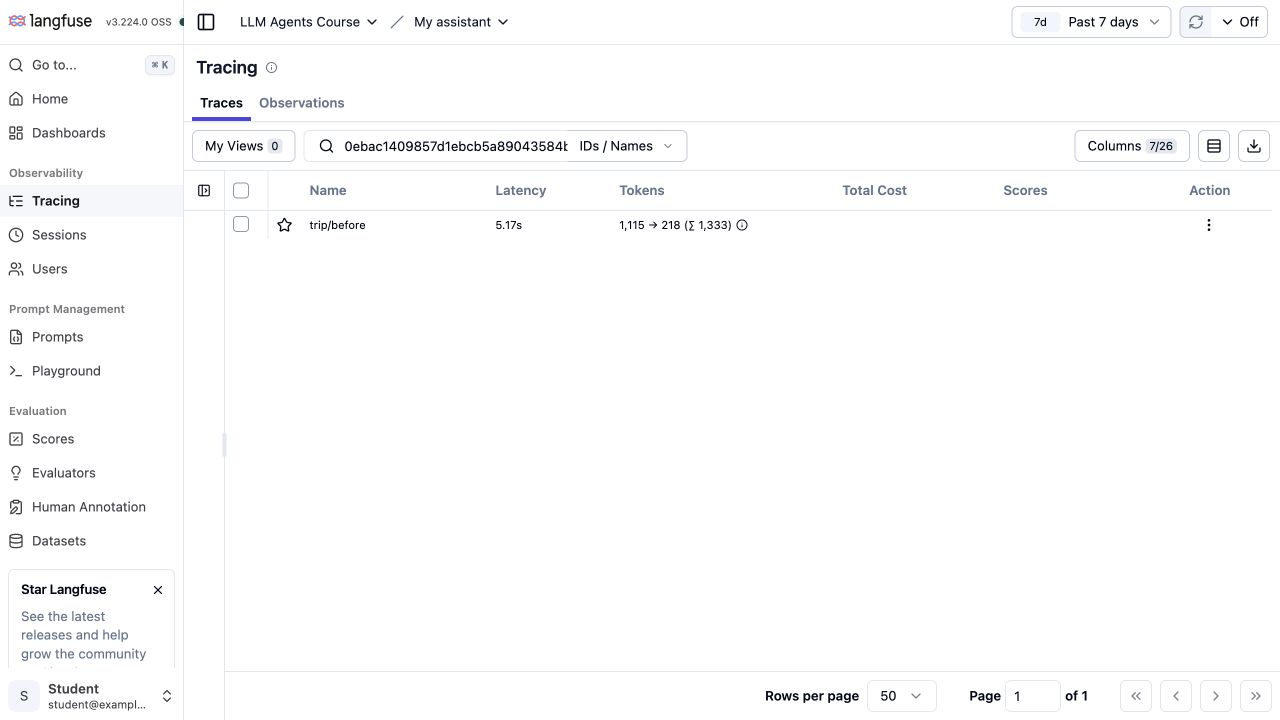


In [ ]:
# Показать рубли из ответов Polza рядом с отдельным полем Langfuse.


# Первый AIMessage запрашивает инструмент; это тоже обращение к модели.
first_reply = next(message for message in before["result"]["messages"] if message.type == "ai")
print("Usage metadata:", first_reply.usage_metadata)
print("Provider charge, RUB:", first_reply.response_metadata.get("token_usage", {}).get("cost_rub"))
print("Whole invocation, RUB:", before["metrics"]["cost_rub"])
print("Langfuse built-in cost, USD:", before_trace.total_cost)


### Проверяем, знает ли Langfuse цену модели

В интерфейсе 3.224.0 откройте `Settings → Model Definitions → Test Model Match`.
В `Model Name` вставьте имя из шапки записи `ChatOpenAI` и нажмите `Test Match`.
Для учебного `deepseek/deepseek-v4.1-flash` проверка вернула `No Match Found`: подходящей настройки цены в этом проекте нет.

Если нужен расчет USD, закройте проверку и выберите `Add Model Definition`. Определение должно соответствовать имени модели и тарифу вашего провайдера.
Цены задаются за единицу: цену за миллион токенов нужно разделить на миллион. Названия типов расхода должны совпасть с `usage_details`.
Возможные типы: `input`, `input_cache_read`, `output`; набор зависит от данных, которые присылает интеграция.
После сохранения выполните новый запрос. Прежние записи автоматически не пересчитаются; подробности есть в [документации Langfuse](https://langfuse.com/docs/observability/features/token-and-cost-tracking).
В этом занятии сравнение расходов в рублях использует готовый `cost_rub` от Polza; для него настройка тарифов Langfuse не требуется.

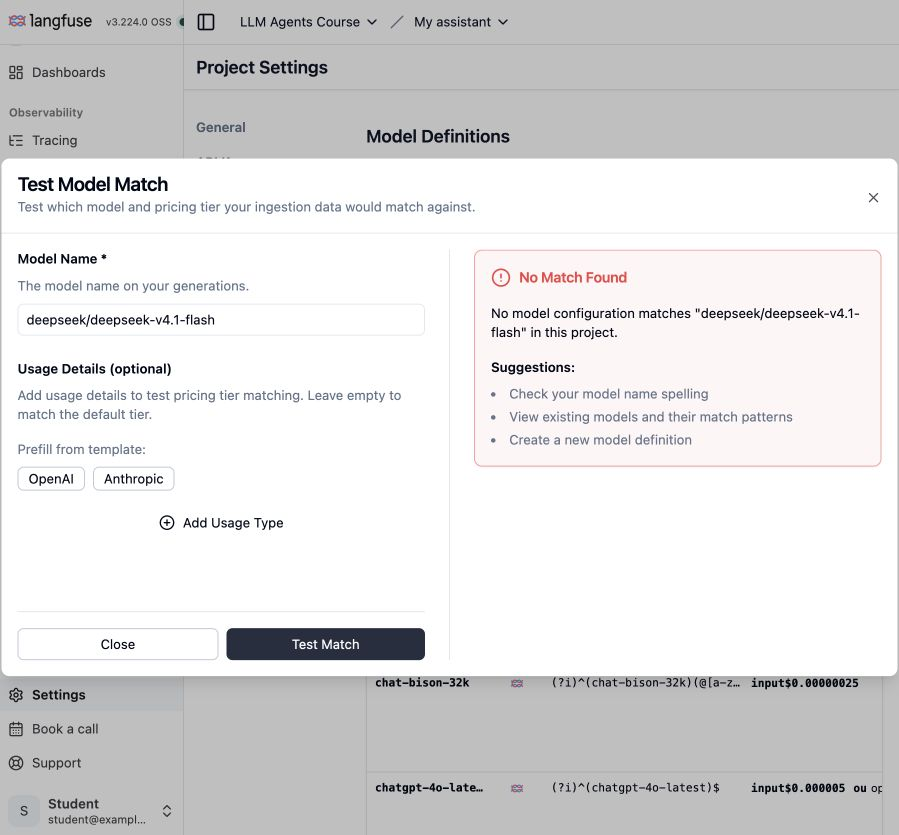


## Убираем отдельную редактуру

В трейсе видно, что `polish` получает уже готовый маршрут. Проверим, достаточно ли указать желаемый тон сразу в системном промпте.
Ниже создается тот же `create_agent` с тем же инструментом и моделью. Отдельный хук редактуры больше не подключается.
Для сравнения нужен новый разговор и тот же вопрос: предыдущая переписка изменила бы объем контекста.

После запуска сравните сами ответы. Помимо числа вызовов важно, сохранились ли нужные места, понятен ли маршрут и не появились ли выдуманные сведения.


In [ ]:
# Попросить нужный тон сразу при составлении маршрута.

FRIENDLY_PROMPT = PLAN_PROMPT + " Use a warm, friendly tone."
fixed = create_agent(
    model=model, tools=[city_sights], system_prompt=FRIENDLY_PROMPT,
    checkpointer=InMemorySaver(),
)


In [ ]:
# Записать исправленный вариант в Langfuse и сравнить отчеты.

from IPython.display import Markdown, display

after = run_trip(fixed, QUESTION, trace_config("after"))
print(after["result"]["messages"][-1].content)
print("Trace:", after["url"])

rows = ["| Показатель | До | После |", "|---|---:|---:|"]
for key, title in [
    ("model_calls", "Вызовы модели"), ("seconds", "Время, с"),
    ("input_tokens", "Входные токены"), ("output_tokens", "Выходные токены"),
    ("cost_rub", "Расход Polza, руб."),
]:
    # None останется видимым, если провайдер не передал поле.
    values = [run["metrics"][key] for run in (before, after)]
    rows.append(f"| {title} | {values[0]} | {values[1]} |")
display(Markdown("\n".join(rows)))


In [ ]:
# Сравнить число вызовов, ожидание и расходы двух прогонов Langfuse.

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained")
for ax, key, title in zip(
    axes, ["model_calls", "seconds", "cost_rub"],
    ["Вызовы модели", "Время ответа, с", "Расход Polza, руб."],
):
    values = [run["metrics"][key] for run in (before, after)]
    ax.set_title(title, fontsize=12)
    # Отсутствие цены нельзя изобразить нулевым столбцом.
    if any(value is None for value in values):
        ax.text(0.5, 0.5, "Провайдер не передал стоимость", ha="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    bars = ax.bar(["До", "После"], values, color=["#c87b36", "#416d9c"])
    ax.bar_label(bars, fmt="%.4g", padding=4)
    ax.set_ylim(0, max(values) * 1.25 or 1)
    ax.spines[["top", "right"]].set_visible(False)
    if key == "model_calls":
        ax.set_yticks(range(int(max(values)) + 1))
plt.show()


### Что можно заключить из сравнения

Если поиск прошел за один вызов инструмента, исходный вариант обращается к модели трижды, исправленный дважды.
Второй вариант обходится без запроса, который занимался только тоном. Время и расход каждого прогона показаны на графиках выше.
Один замер не устанавливает постоянный процент ускорения: влияют длина ответа, кеш и текущая задержка провайдера.
Для продуктового решения сравнение стоит повторить на одинаковом наборе запросов и проверить качество ответов.


## Два сообщения пользователя в одном диалоге

Пользователь получил маршрут и уточнил: «А если будет дождь?» Это новый прогон агента в том же разговоре.
Для обоих вызовов ниже передается один `dialogue_config`. Чекпоинтер подгрузит прежнюю переписку, а Langfuse соберет два трейса в одну сессию.
Вторая строка `Metrics` считает только новый запрос. Расходы всего диалога получаются сложением сумм двух ходов.
При новом запуске этой ячейки создается другой идентификатор, поэтому вчерашние прогоны в диалог не попадут.

Проверьте и содержание ответа: каталог содержит краткие описания, но не гарантирует наличие крытых мест или актуальность часов работы.

После запуска откройте один из двух трейсов и нажмите плашку `Session: ...` вверху.
На странице сессии проверьте `Total traces: 2` и найдите оба сообщения: исходный вопрос и уточнение про дождь.
В сохраненном примере `Total cost: $0.00` тоже не отражает рублевую сумму Polza.

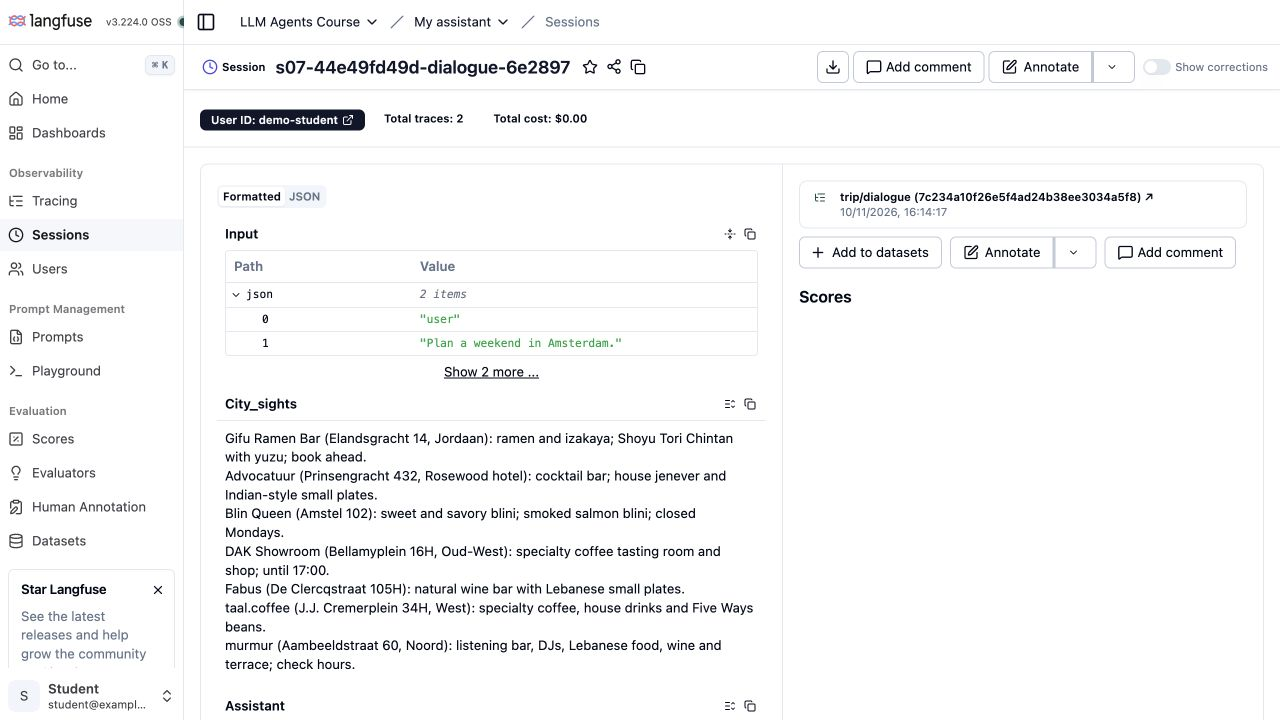


In [ ]:
# Провести диалог и найти его два трейса в одной сессии Langfuse.

dialogue_config = trace_config("dialogue")  # создать один раз на оба хода
turn_one = run_trip(fixed, QUESTION, dialogue_config)

# Второй вопрос добавляется к истории первого.
turn_two = run_trip(fixed, "Now adapt that plan for a rainy day.", dialogue_config)
print(turn_two["result"]["messages"][-1].content)
print("Session:", dialogue_config["metadata"]["langfuse_session_id"])
print("First turn:", turn_one["metrics"])
print("Second turn:", turn_two["metrics"])
print("Traces:", turn_one["url"], turn_two["url"], sep="\n")


## Меняем промпт и видим, какая версия работала

Теперь требуется изменить формат ответа: вместо одного абзаца показывать два пункта, по одному на день.
В Langfuse текст промпта сохраняется как версия. Метка `production` указывает, какую версию должен брать агент.
Новая версия сама по себе не обязана становиться рабочей: сначала ее можно сохранить с другой меткой.

Пройдем весь путь: сохранить первую версию, выполнить запрос, создать вторую, перенести `production`, выполнить запрос еще раз и проверить связь в трейсе.
Имя учебного промпта включает `lesson_id`, поэтому Run All не меняет промпты других примеров или проектов.

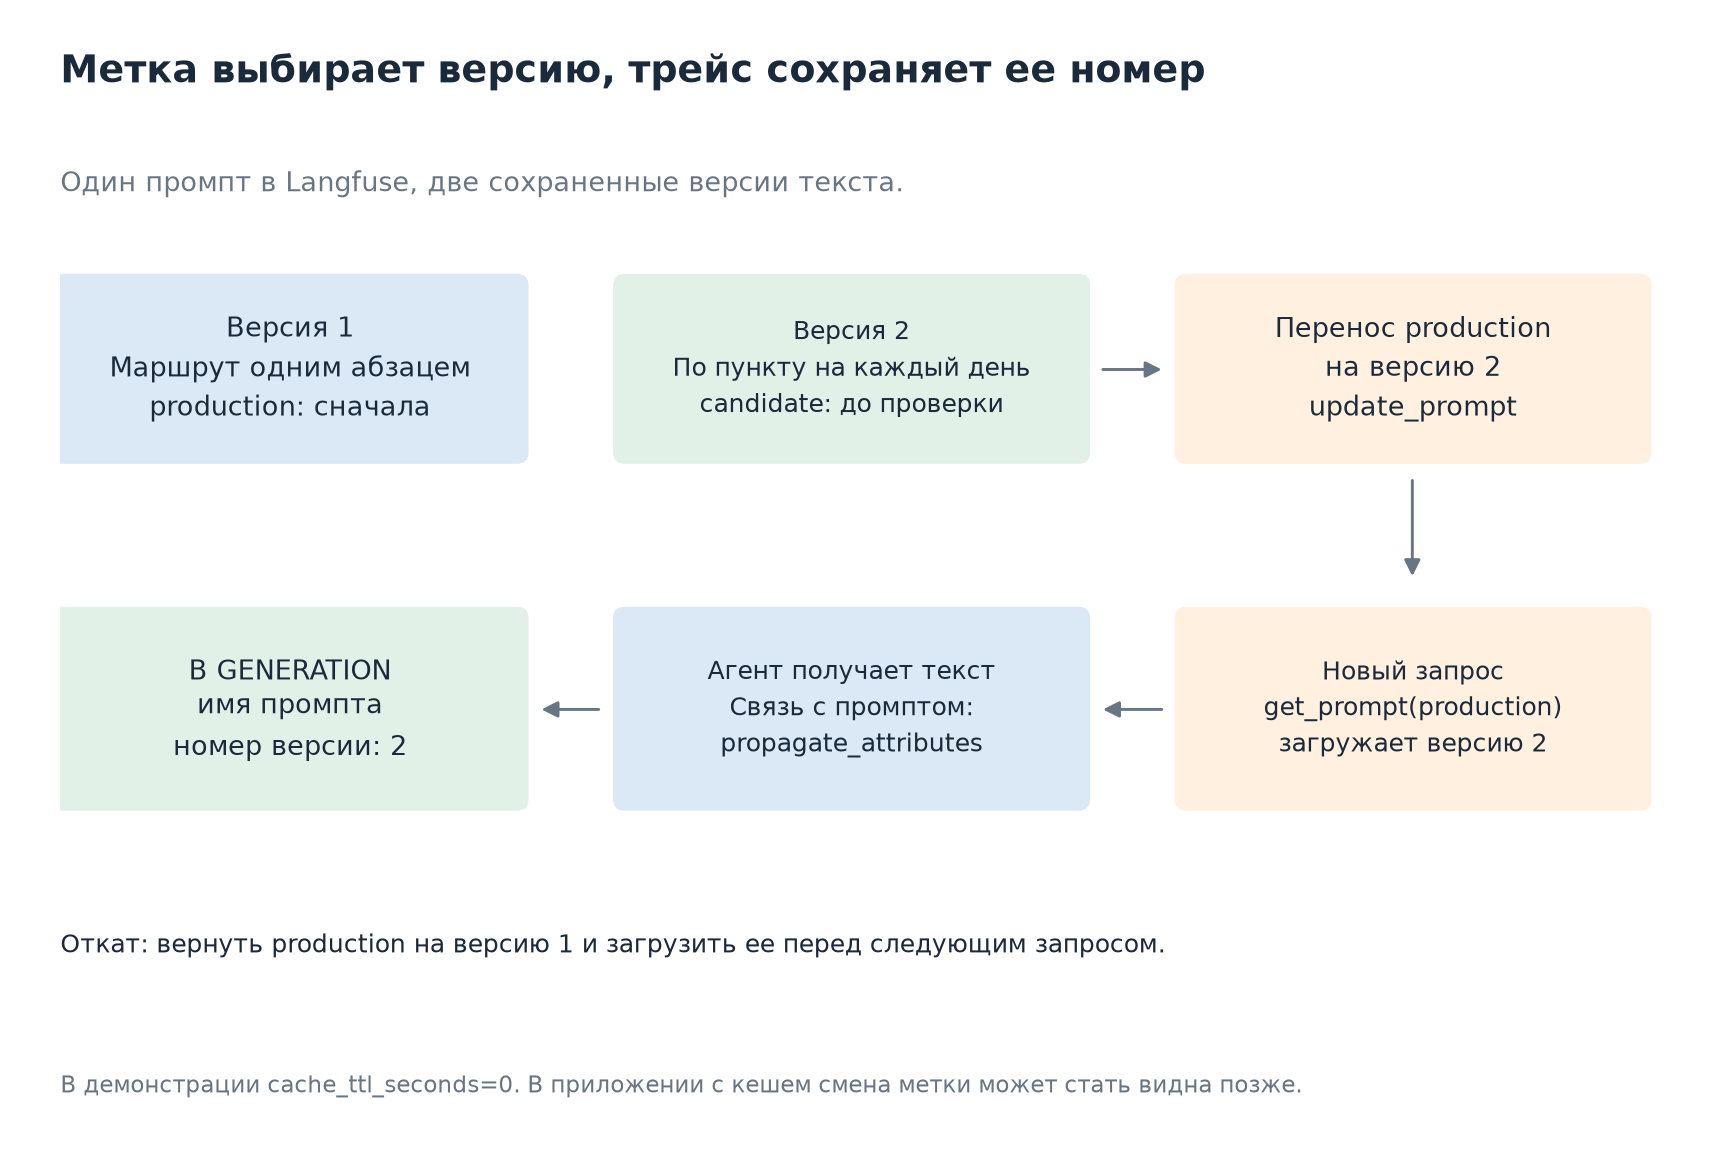


In [ ]:
# Сохранить первую версию учебного промпта в Langfuse.

prompt_name = f"course-trip-{lesson_id}"  # отдельное имя для этого Run All
prompt_v1 = langfuse.create_prompt(
    name=prompt_name, prompt=FRIENDLY_PROMPT, labels=["production"],
)
print("Prompt:", prompt_v1.name, "| version:", prompt_v1.version)


### Где загружается промпт

Функция ниже получает рабочую версию перед каждым пользовательским запросом и собирает агента с ее текстом.
В пределах одного запроса версия остается той же. Сборка `create_agent` сама не вызывает модель.
`propagate_attributes(prompt=prompt)` связывает обращения к модели с полученной версией в Langfuse.

Для демонстрации кеш отключен через `cache_ttl_seconds=0`, чтобы смена метки была видна сразу.
В сервисе обычно оставляют кеш SDK и учитывают задержку обновления; загрузка один раз при старте не подхватит правки сама.
Здесь каждый пример начинает отдельный разговор. В приложении чекпоинтер и идентификатор существующего диалога нужно сохранить.


In [ ]:
# Загрузить рабочий промпт и связать вызовы модели с его версией в Langfuse.

from langfuse import propagate_attributes


def ask_with_managed_prompt(question, label):
    # Перечитать метку перед запросом; кеш отключен для демонстрации.
    prompt = langfuse.get_prompt(prompt_name, label="production", cache_ttl_seconds=0)
    # Новая сборка использует уже загруженный текст, модель пока не вызывается.
    agent = create_agent(
        model=model, tools=[city_sights], system_prompt=prompt.compile(),
        checkpointer=InMemorySaver(),
    )
    # Во всех вызовах модели этого запроса используется один загруженный промпт.
    with propagate_attributes(prompt=prompt):
        run = run_trip(agent, question, trace_config(label))
    return run, prompt


version_one_run, used_v1 = ask_with_managed_prompt(QUESTION, "prompt-v1")
print(version_one_run["result"]["messages"][-1].content)
print("Used version:", used_v1.version)
print("Trace:", version_one_run["url"])


In [ ]:
# Проверить привязку промпта по фактическим генерациям в Langfuse.

version_one_trace = read_trace(version_one_run)

# Проверяется запись на сервере, а не только локальный объект prompt.
linked_v1 = [item for item in version_one_trace.observations if item.type == "GENERATION"]
print([(item.prompt_name, item.prompt_version) for item in linked_v1])
assert all(item.prompt_name == prompt_name and item.prompt_version == used_v1.version for item in linked_v1)


### Переключаем формат ответа

Следующая ячейка сохраняет другой текст под тем же именем с меткой `candidate`.
Проверка перед переключением подтверждает, что `production` все еще указывает на первую версию.
Затем `update_prompt` переносит рабочую метку на вторую версию. Следующий пользовательский запрос загрузит ее заново.
В выводе должны измениться номер версии и формат маршрута; в трейсе появится привязка к новому номеру.

Для показа в браузере: `Prompts → имя из вывода → #2`. Прочитайте требование про два пункта в `Text Prompt`.
Кнопка `Add prompt label` рядом с метками открывает выбор: `production → Save` назначает эту версию рабочей.
После выполнения кода откройте трейс `prompt-v2`, выберите `ChatOpenAI` и найдите плашку `Prompt: ... - v2`.
Версия на этой плашке относится к прошлому вызову; последующий откат метки ее не изменит.
На вкладке `Linked Generations` у версии промпта можно открыть те же вызовы со стороны промпта.

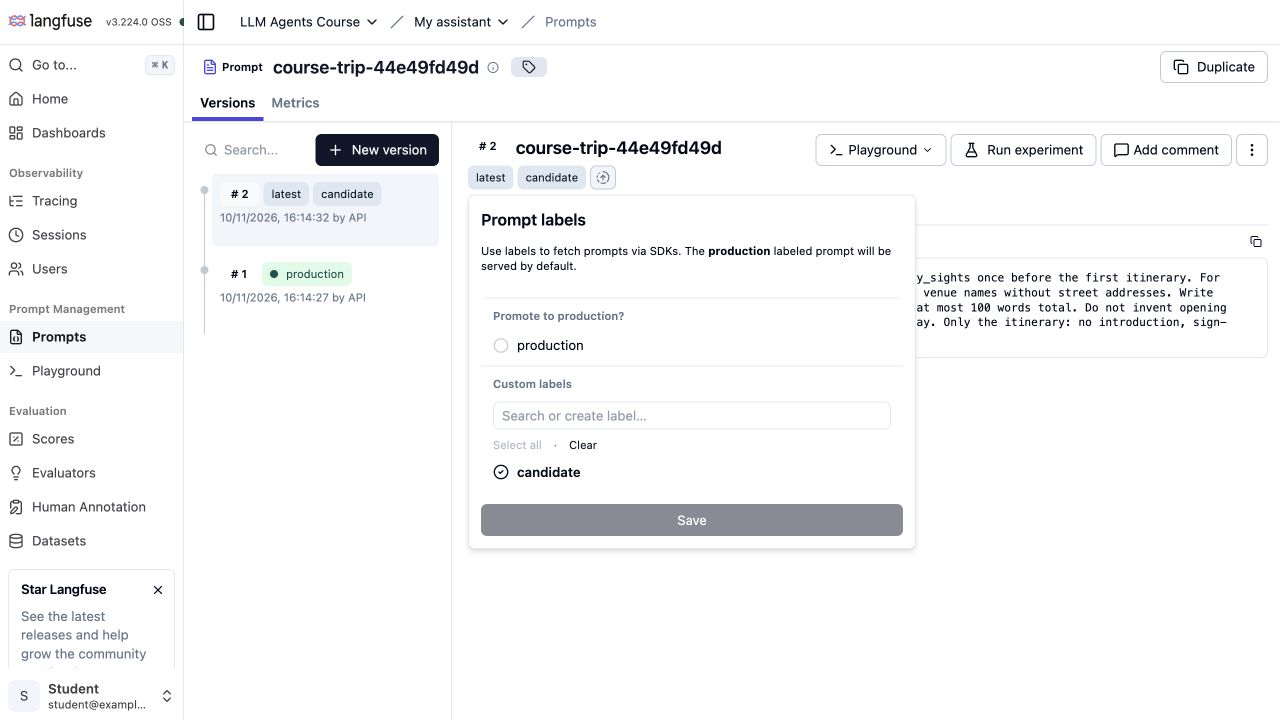


In [ ]:
# Создать вторую версию и переключить рабочую метку Langfuse.


# Меняется только формат; инструмент и остальные требования остаются.
TWO_DAYS_PROMPT = FRIENDLY_PROMPT.replace(
    "Write one paragraph, at most 100 words.",
    "Write exactly two bullet points, one for Saturday and one for Sunday, at most 100 words total.",
)
prompt_v2 = langfuse.create_prompt(
    name=prompt_name, prompt=TWO_DAYS_PROMPT, labels=["candidate"],
)
still_v1 = langfuse.get_prompt(prompt_name, label="production", cache_ttl_seconds=0)
assert still_v1.version == prompt_v1.version


# Теперь следующий запрос должен получить новую версию.
langfuse.update_prompt(name=prompt_name, version=prompt_v2.version, new_labels=["production"])
version_two_run, used_v2 = ask_with_managed_prompt(QUESTION, "prompt-v2")
print(version_two_run["result"]["messages"][-1].content)
print("Used version:", used_v2.version)
print("Trace:", version_two_run["url"])

linked_v2 = [item for item in read_trace(version_two_run).observations if item.type == "GENERATION"]
assert used_v2.version == prompt_v2.version
assert all(item.prompt_name == prompt_name and item.prompt_version == used_v2.version for item in linked_v2)
print("Linked prompt versions:", [(item.prompt_name, item.prompt_version) for item in linked_v2])


In [ ]:
# Вернуть рабочую метку Langfuse на прежнюю версию без удаления истории.

langfuse.update_prompt(name=prompt_name, version=prompt_v1.version, new_labels=["production"])

# Повторное чтение подтверждает, куда указывает рабочая метка.
restored_prompt = langfuse.get_prompt(prompt_name, label="production", cache_ttl_seconds=0)
assert restored_prompt.version == prompt_v1.version
print("Production restored to version:", restored_prompt.version)


## Тест для кода, которому уже доверили отчет

Если провайдер не сообщил стоимость, в отчете должно остаться `None`. Ошибка, которая подменит отсутствие данных нулем, сделает отчет неправдоподобно дешевым.
Это можно проверить без обращения к модели: создать несколько сообщений с известными расходами и передать их той же функции `summarize_run`.
Ниже показан исходный файл функции. Следующий тест импортирует именно его, как и код измерений выше.
Функция агента или расчета внутри теста заново не объявляется.

Такой тест проверяет подсчет и обработку пропусков. Хорош ли маршрут для пользователя, он не устанавливает; для этого нужны отдельные примеры и оценка ответов.


In [ ]:
# Прочитать исходный код той функции, которая формирует отчет.

import inspect
import lesson07_metrics

print(inspect.getsource(lesson07_metrics.summarize_run))


In [ ]:
# Подготовить тесты реального модуля отчета.

TEST_SOURCE = r'''import pytest
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage
from lesson07_metrics import summarize_run


def reply(cost):
    # Заданные числа проверяют расчет без платного вызова модели.
    usage = {"input_tokens": 10, "output_tokens": 2, "total_tokens": 12}
    # None означает, что провайдер не прислал поле стоимости.
    metadata = {"token_usage": {}} if cost is None else {"token_usage": {"cost_rub": cost}}
    return AIMessage(content="Ready", usage_metadata=usage, response_metadata=metadata)


def test_only_model_replies_are_counted():
    messages = [HumanMessage("Plan"), reply(0.02), ToolMessage("Sights", tool_call_id="x"), reply(0.03)]
    report = summarize_run(messages, 1.25)
    assert report["model_calls"] == 2
    assert report["input_tokens"] == 20
    assert report["output_tokens"] == 4
    assert report["cost_rub"] == pytest.approx(0.05)


def test_missing_cost_does_not_become_a_partial_total():
    report = summarize_run([reply(0.02), reply(None)], 1.0)
    assert report["cost_rub"] is None


def test_explicit_zero_cost_is_preserved():
    assert summarize_run([reply(0.0)], 1.0)["cost_rub"] == 0.0


def test_missing_usage_stays_unknown():
    report = summarize_run([AIMessage(content="Ready")], 1.0)
    assert report["input_tokens"] is None
    assert report["output_tokens"] is None
'''
print(TEST_SOURCE)


In [ ]:
# Запустить тесты в отдельном процессе Python.

import subprocess
import sys
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory(prefix="session07-tests-") as folder:
    test_path = Path(folder) / "test_metrics.py"
    test_path.write_text(TEST_SOURCE)  # временный файл удалится после проверки
    # Подпроцесс импортирует тот же модуль рядом с ноутбуком.
    environment = {**os.environ, "PYTHONPATH": str(Path(lesson07_metrics.__file__).parent)}
    report = subprocess.run(
        [sys.executable, "-m", "pytest", str(test_path), "-q"],  # Python того же окружения
        capture_output=True, text=True, env=environment,
    )
    print(report.stdout)
    assert report.returncode == 0, report.stdout + report.stderr


## Практика на своем агенте

Подключите `CallbackHandler`, задайте имя прогона и уникальный идентификатор диалога. Выполните запрос, который пользователю приходится долго ждать.
По трейсу найдите конкретную причину задержки: лишнее обращение к модели, медленный инструмент или слишком длинный ответ.
Внесите одну правку и повторите тот же запрос в новом разговоре. Сравните расходы и результат для пользователя.

Перенесите один промпт в Langfuse, создайте новую версию и проверьте ее имя и номер в генерации. Убедитесь, что умеете вернуть прежнюю версию.
Добавьте тест для используемой функции своего проекта: например, расчет расхода не должен принимать отсутствующую цену за ноль.
Сохраните тест в репозитории, а ссылки на сравниваемые трейсы и объяснение изменения запишите в `runs/session-07.md`.


## Что пригодится после занятия

Обработчик в `config` записывает ход выполнения. Сессия собирает запросы диалога, а имя и теги помогают найти нужный эксперимент.
По трейсу видно, куда ушло время; ответы модели содержат расход токенов и, у Polza, стоимость в рублях.
Рабочая метка выбирает версию промпта. Приложение должно загрузить ее перед запросом, а трейс должен сохранить, какая версия использована.

- [Подключение LangChain к Langfuse](https://langfuse.com/docs/integrations/langchain/tracing).
- [Привязка промпта к генерациям](https://langfuse.com/docs/prompt-management/features/link-to-traces) и [обновление кеша](https://langfuse.com/faq/all/old-prompt-version-caching).
- [Расход токенов и стоимость](https://langfuse.com/docs/observability/features/token-and-cost-tracking).

На следующем занятии тот же агент будет работать за API и в Telegram. Трейсы помогут разбирать запросы уже после запуска сервиса.
